# Rule-based matching

Precision, recall and F1 on the validation labels, threshold chosen per matcher.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
PAIRS = ["wikidata-ror", "deqar-ror"]

In [2]:
matching = pd.read_csv("results/matching.csv")
matching[["round", "pair", "matcher", "threshold", "P", "R", "F1", "corr", "seconds"]]

,round,pair,matcher,threshold,P,R,F1,corr,seconds
0,1,wikidata-ror,name Levenshtein 0.5 + year 0.5,0.30,1.000,0.876,0.934,133694,33.5
1,1,wikidata-ror,name Levenshtein 0.7 + year 0.3,0.30,1.000,0.876,0.934,219854,35.2
2,1,wikidata-ror,name Levenshtein only,0.30,1.000,0.876,0.934,306082,31.1
3,1,deqar-ror,name Levenshtein 0.5 + year 0.5,0.30,1.000,0.658,0.794,41304,12.4
4,1,deqar-ror,name Levenshtein 0.7 + year 0.3,0.30,1.000,0.664,0.798,72191,13.2
5,1,deqar-ror,name Levenshtein only,0.30,1.000,0.664,0.798,111651,13.8
6,2,wikidata-ror,name Levenshtein,0.30,0.661,0.833,0.737,435504,42.9
7,2,wikidata-ror,name Jaro-Winkler,0.50,0.662,0.993,0.794,730509,42.1
8,2,wikidata-ror,name Jaccard (words),0.30,0.632,0.710,0.669,208303,50.7
9,2,wikidata-ror,"best of all names, Jaro-Winkler",0.30,0.659,0.993,0.792,754122,64.1


In [3]:
def plot_matching(df, rnd):
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * df["matcher"].nunique() + 1.5), sharey=True)
    for ax, pair in zip(axes, PAIRS):
        part = df[(df["round"] == rnd) & (df["pair"] == pair)].set_index("matcher")[["P", "R", "F1"]]
        part.plot.barh(ax=ax, width=0.8, legend=False)
        ax.set_xlim(0, 1)
        ax.set_title(f"round {rnd}: {pair}")
        ax.set_ylabel("")
    fig.legend(["P", "R", "F1"], loc="upper center", ncol=3)
    plt.tight_layout(rect=(0, 0, 1, 0.93))

## Round 1: rule of the exercise notebook (easy labels)

Precision is 1.0 because the random non-matches are far too easy.

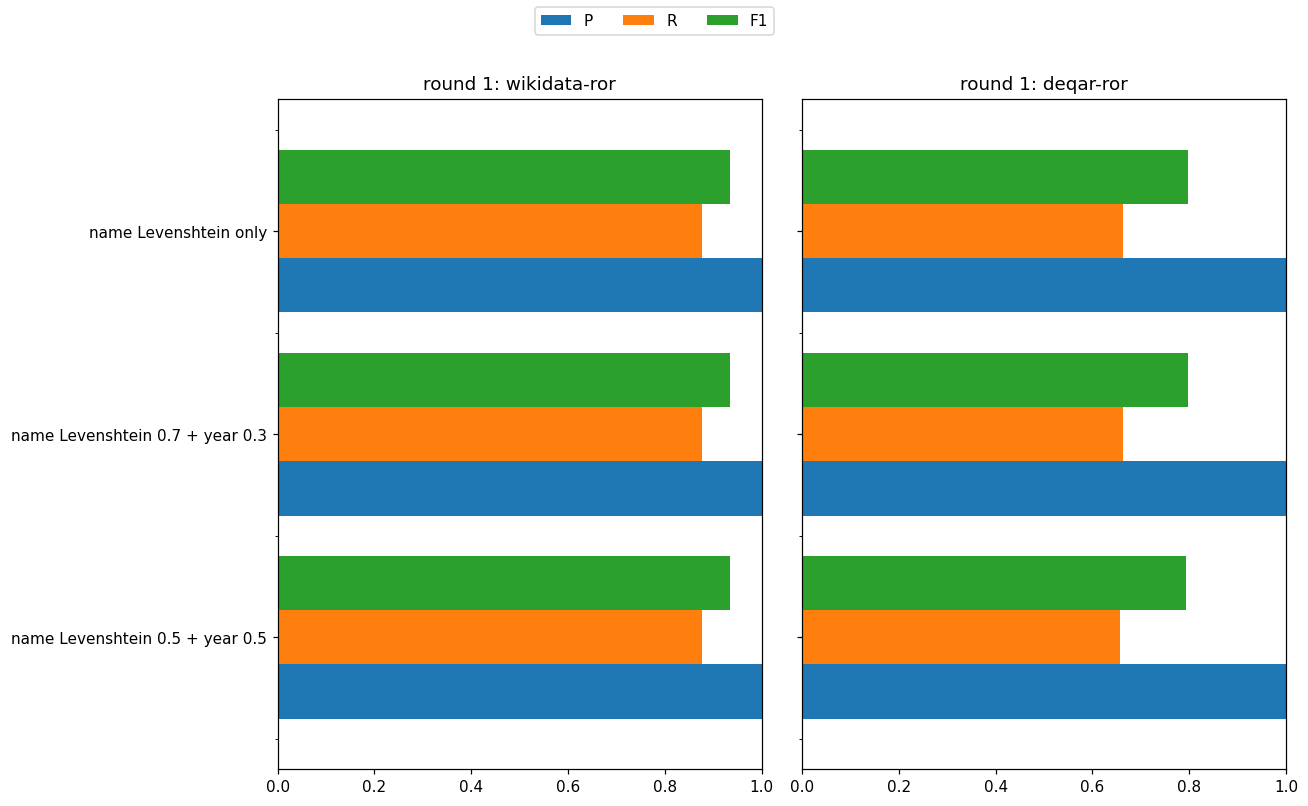

In [4]:
plot_matching(matching, 1)

## Round 2: every name measure alone, then rules with more attributes

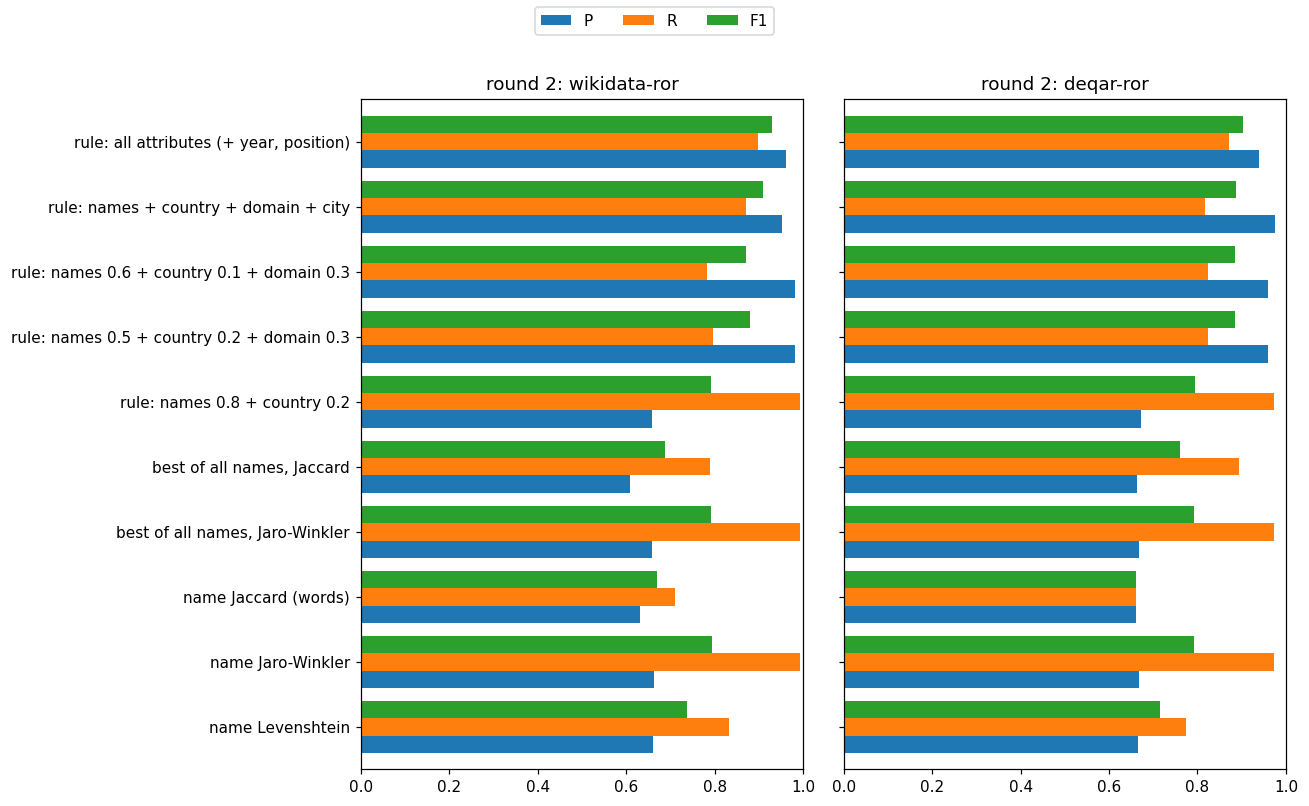

In [5]:
plot_matching(matching, 2)

## Round 3: the best ones again, with translated names

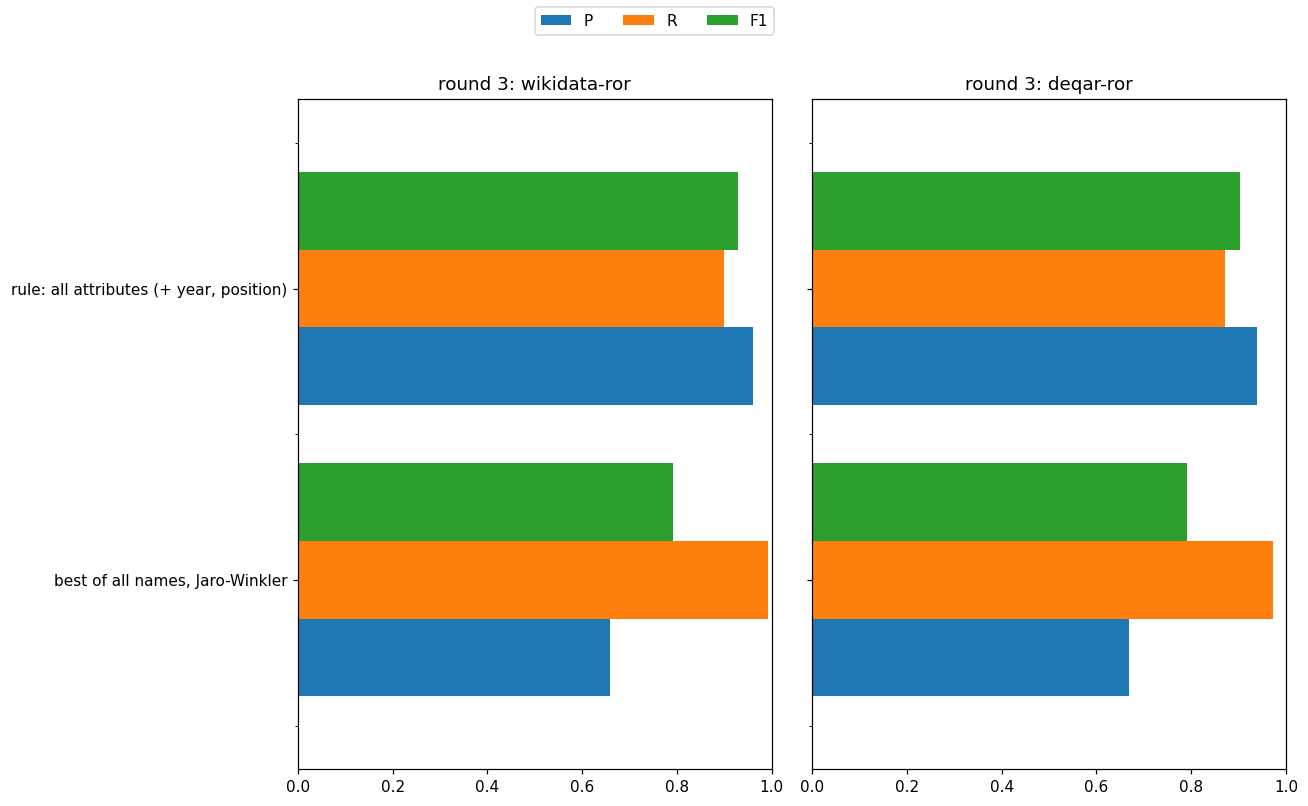

In [6]:
plot_matching(matching, 3)

## Number of correspondences

Name-only measures produce hundreds of thousands of correspondences.

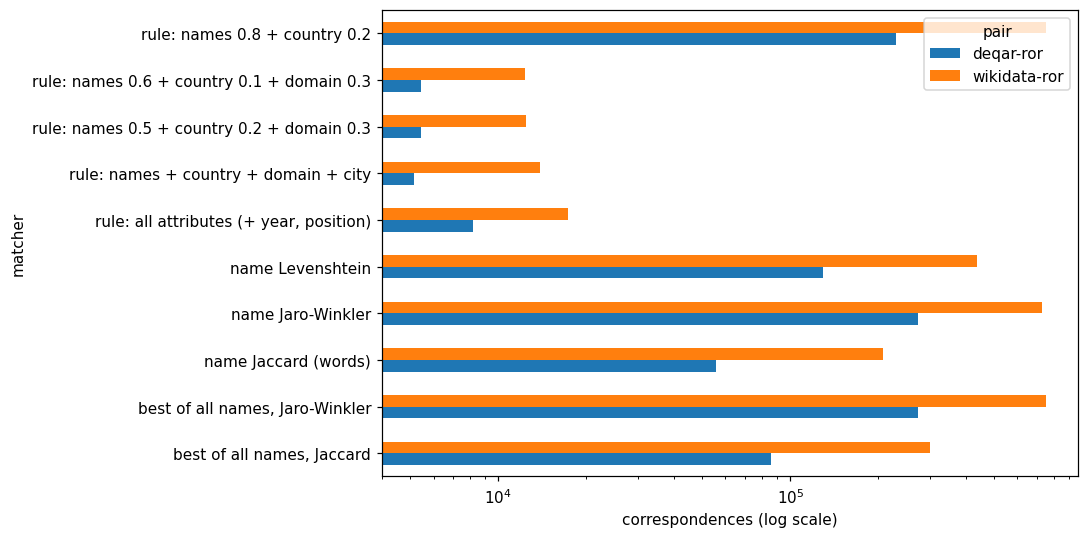

In [7]:
part = matching[matching["round"] == 2].pivot(index="matcher", columns="pair", values="corr")
part.plot.barh(figsize=(10, 5), logx=True)
plt.xlabel("correspondences (log scale)")
plt.tight_layout()